In [1]:
!wget -O /content/rois_gopro.zip "https://pub-e8bbdcbe8f6243b2a9933704a9b1d8bc.r2.dev/parking%2Frois_gopro.zip"
!unzip -o /content/rois_gopro.zip -d /content/data/ACPDS | tail -5

--2026-11-25 22:18:03--  https://pub-e8bbdcbe8f6243b2a9933704a9b1d8bc.r2.dev/parking%2Frois_gopro.zip
Resolving pub-e8bbdcbe8f6243b2a9933704a9b1d8bc.r2.dev (pub-e8bbdcbe8f6243b2a9933704a9b1d8bc.r2.dev)... 104.18.50.34, 104.18.54.45, 2606:4700:311b::6812:362d, ...
Connecting to pub-e8bbdcbe8f6243b2a9933704a9b1d8bc.r2.dev (pub-e8bbdcbe8f6243b2a9933704a9b1d8bc.r2.dev)|104.18.50.34|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 380796292 (363M)
Saving to: ‘/content/rois_gopro.zip’

/content/rois_gopro 100%[===================>] 363.16M  50.3MB/s    in 7.3s    

2026-11-25 22:18:11 (49.6 MB/s) - ‘/content/rois_gopro.zip’ saved [380796292/380796292]

  inflating: /content/data/ACPDS/images/GOPR6689.JPG  
  inflating: /content/data/ACPDS/images/GOPR6676.JPG  
  inflating: /content/data/ACPDS/images/GOPR6662.JPG  
  inflating: /content/data/ACPDS/images/GOPR6702.JPG  
  inflating: /content/data/ACPDS/images/GOPR6716.JPG  


In [2]:
!mkdir -p /content/data/ACPDS
!unzip -q -o /content/rois_gopro.zip -d /content/data/ACPDS
!find /content/data/ACPDS -maxdepth 2 | head

/content/data/ACPDS
/content/data/ACPDS/images
/content/data/ACPDS/images/GOPR6561.JPG
/content/data/ACPDS/images/GOPR6771.JPG
/content/data/ACPDS/images/GOPR6740.JPG
/content/data/ACPDS/images/GOPR6568.JPG
/content/data/ACPDS/images/GOPR6655.JPG
/content/data/ACPDS/images/GOPR6692.JPG
/content/data/ACPDS/images/GOPR6746.JPG
/content/data/ACPDS/images/GOPR6777.JPG


In [3]:
import json, glob, os, zipfile
from PIL import Image, ImageDraw, ImageFont

ann_path = glob.glob('/content/data/ACPDS/**/annotations.json', recursive=True)[0]
ACPDS_ROOT = os.path.dirname(ann_path)
acpds = json.load(open(ann_path))
print('Raíz:', ACPDS_ROOT)
print('Claves:', list(acpds.keys()))
for split in ('train', 'valid', 'test'):
    d = acpds[split]
    print(f"{split:5s}: {len(d['file_names'])} imágenes, {sum(len(o) for o in d['occupancy_list'])} plazas")
d = acpds['train']
print('Ejemplo:', d['file_names'][0], '| 1.ª plaza:', d['rois_list'][0][0], '| ocupación:', d['occupancy_list'][0][:5])
with Image.open(os.path.join(ACPDS_ROOT, 'images', d['file_names'][0])) as im:
    print('Tamaño de imagen:', im.size)

Raíz: /content/data/ACPDS
Claves: ['train', 'valid', 'test']
train: 231 imágenes, 7842 plazas
valid: 35 imágenes, 1904 plazas
test : 27 imágenes, 1490 plazas
Ejemplo: GOPR0025.JPG | 1.ª plaza: [[0.3330645, 0.5182796666666667], [0.2903225, 0.62043], [0.14516125, 0.4978493333333333], [0.18629025, 0.42365600000000003]] | ocupación: [True, True, True, False, True]
Tamaño de imagen: (4000, 3000)


In [4]:
REV_DIR = '/content/acpds_revision'
os.makedirs(REV_DIR, exist_ok=True)
WIDTH = 1200
try:
    font = ImageFont.truetype('/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf', 18)
except OSError:
    font = ImageFont.load_default()

for split in ('train', 'valid', 'test'):
    d = acpds[split]
    for fname, rois, occ in zip(d['file_names'], d['rois_list'], d['occupancy_list']):
        with Image.open(os.path.join(ACPDS_ROOT, 'images', fname)) as im:
            W, H = im.size
            scale = WIDTH / W
            im = im.convert('RGB').resize((WIDTH, round(H * scale)))
        normalized = max(max(p) for roi in rois for p in roi) <= 1.0
        draw = ImageDraw.Draw(im)
        for i, (roi, o) in enumerate(zip(rois, occ)):
            pts = [((x * W if normalized else x) * scale, (y * H if normalized else y) * scale) for x, y in roi]
            color = (255, 60, 60) if o else (60, 220, 60)
            draw.polygon(pts, outline=color, width=2)
            cx = sum(p[0] for p in pts) / 4; cy = sum(p[1] for p in pts) / 4
            draw.text((cx, cy), str(i), fill=(255, 255, 0), font=font, anchor='mm',
                      stroke_width=2, stroke_fill=(0, 0, 0))
        draw.text((10, 10), f'{split} · {fname}', fill=(255, 255, 255), font=font,
                  stroke_width=2, stroke_fill=(0, 0, 0))
        im.save(os.path.join(REV_DIR, f'{split}__{os.path.splitext(fname)[0]}.jpg'), quality=80)

zip_path = '/content/acpds_revision.zip'
with zipfile.ZipFile(zip_path, 'w') as z:
    for f in sorted(os.listdir(REV_DIR)):
        z.write(os.path.join(REV_DIR, f), f)
print('Imágenes de revisión:', len(os.listdir(REV_DIR)), '| zip:', round(os.path.getsize(zip_path) / 1024**2, 1), 'MB')

from google.colab import files
files.download(zip_path)

Imágenes de revisión: 293 | zip: 67.7 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
import json, glob, os

BASE = '/content'
from collections import Counter
from PIL import Image

ann_path = glob.glob(f'{BASE}/data/ACPDS/**/annotations.json', recursive=True)[0]
ACPDS_ROOT = os.path.dirname(ann_path)
OUT_DIR = f'{BASE}/data/ACPDS-coco'
MAX_SIDE = 1280      # lado mayor tras redimensionar (como Meta-PKLot-mini)
DEC = 2

CATEGORIES = [
    {'id': 1, 'name': 'empty', 'supercategory': 'parking_spot'},
    {'id': 2, 'name': 'occupied', 'supercategory': 'parking_spot'},
]
DATASETS = [{'id': 3, 'name': 'ACPDS', 'subsets': [{'id': 13, 'name': 'acpds'}]}]
SPLITS = ('train', 'valid', 'test')


# Plazas con una X pintada en el suelo (revisión manual de las 293 imágenes).
# Clave = nombre del archivo original; valor = índices de plaza dentro de esa imagen
# (el mismo orden que rois_list / occupancy_list de annotations.json).
MARKED_X = {
    'GOPR0027.JPG': [1],
    'GOPR0029.JPG': [5, 12, 13, 14, 15],
    'GOPR0042.JPG': [1],
    'GOPR0048.JPG': [5, 6, 7],
    'GOPR0049.JPG': [0, 1, 3, 4, 5, 6, 7, 8],
    'GOPR0056.JPG': [0, 1, 2, 3, 4, 5, 6],
    'GOPR0101.JPG': [1, 3, 7, 8, 9],
    'GOPR6549.JPG': [0],
    'GOPR6550.JPG': [0, 1],
    'GOPR6559.JPG': [1, 2, 3, 4, 5, 6, 7, 8, 9],
    'GOPR6569.JPG': [1, 13, 17, 18, 19],
    'GOPR6570.JPG': [2, 3],
    'GOPR6581.JPG': [16, 17, 18, 19, 20, 21, 22, 23],
    'GOPR6583.JPG': [7, 8, 9],
    'GOPR6603.JPG': [14, 15, 16, 17, 18],
    'GOPR6659.JPG': [0, 1],
    'GOPR6660.JPG': [3],
    'GOPR6661.JPG': [0, 1, 2, 8, 9, 19],
    'GOPR6664.JPG': [0, 1, 2, 7, 12, 13],
    'GOPR6665.JPG': [0, 1, 2, 3, 4, 5],
    'GOPR6669.JPG': [0, 1, 2, 3, 4],
    'GOPR6673.JPG': [1, 2, 3, 4, 5, 6, 7, 8, 9],
    'GOPR6675.JPG': [8, 9, 10, 11, 12, 13],
    'GOPR6676.JPG': [0, 1, 2, 3, 4],
    'GOPR6677.JPG': [5, 7],
    'GOPR6678.JPG': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
    'GOPR6679.JPG': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
    'GOPR6680.JPG': [0, 1, 2, 3, 5, 6, 7, 8, 13],
    'GOPR6681.JPG': [0, 1, 2, 3, 4],
    'GOPR6682.JPG': [0],
    'GOPR6683.JPG': [0, 6, 7, 8],
    'GOPR6684.JPG': [0, 1, 4],
    'GOPR6686.JPG': [15],
    'GOPR6687.JPG': [0],
    'GOPR6688.JPG': [0, 5, 6, 7, 8, 11, 12, 13],
    'GOPR6690.JPG': [0, 1, 2, 3, 4, 5, 6],
    'GOPR6691.JPG': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11],
    'GOPR6692.JPG': [9],
    'GOPR6693.JPG': [0, 12],
    'GOPR6696.JPG': [0, 1, 7, 8],
    'GOPR6697.JPG': [0, 6, 7],
    'GOPR6731.JPG': [0, 1],
    'GOPR6732.JPG': [16, 17, 18, 19],
    'GOPR6735.JPG': [13],
    'GOPR6733.JPG': [18, 19, 20, 32, 33],
    'GOPR6738.JPG': [0],
    'GOPR6761.JPG': [1, 2, 3, 4],
    'GOPR6762.JPG': [6, 7, 8, 9, 10],
    'GOPR6763.JPG': [0, 1],
    'GOPR6764.JPG': [0, 54],
    'GOPR6784.JPG': [1],
}


def _polygon_area(pts):
    n = len(pts)
    if n < 3:
        return 0.0
    s = sum(pts[i][0] * pts[(i + 1) % n][1] - pts[(i + 1) % n][0] * pts[i][1] for i in range(n))
    return abs(s) / 2.0


def _clip_polygon(pts, x0, y0, x1, y1):
    """Sutherland-Hodgman contra el rectángulo [x0, x1] x [y0, y1]."""
    def clip(points, inside, intersect):
        out = []
        for i, current in enumerate(points):
            previous = points[i - 1]
            if inside(current):
                if not inside(previous):
                    out.append(intersect(previous, current))
                out.append(current)
            elif inside(previous):
                out.append(intersect(previous, current))
        return out

    def cut_x(xc):
        return lambda p, q: (xc, p[1] + (q[1] - p[1]) * (xc - p[0]) / (q[0] - p[0]))

    def cut_y(yc):
        return lambda p, q: (p[0] + (q[0] - p[0]) * (yc - p[1]) / (q[1] - p[1]), yc)

    for inside, intersect in (
        (lambda p: p[0] >= x0, cut_x(x0)),
        (lambda p: p[0] <= x1, cut_x(x1)),
        (lambda p: p[1] >= y0, cut_y(y0)),
        (lambda p: p[1] <= y1, cut_y(y1)),
    ):
        if not pts:
            break
        pts = clip(pts, inside, intersect)
    return pts


def normalize_acpds_spot(roi, occupied, w, h, normalized, min_visible=0.5):
    """roi = 4 puntos (x, y) de ACPDS. Devuelve la plaza en píxeles de la imagen
    redimensionada (w x h), recortada al borde, o None si se descarta."""
    pts = [((x * w, y * h) if normalized else (x, y)) for x, y in roi]
    original_area = _polygon_area(pts)
    if original_area <= 0:
        return None
    clipped = _clip_polygon(pts, 0, 0, w, h)
    area = _polygon_area(clipped)
    if area < min_visible * original_area:
        return None
    truncated = int(area < original_area - 1e-6)
    pts = [(round(x, DEC), round(y, DEC)) for x, y in clipped]
    xs, ys = [p[0] for p in pts], [p[1] for p in pts]
    bbox = [min(xs), min(ys), round(max(xs) - min(xs), DEC), round(max(ys) - min(ys), DEC)]
    if bbox[2] < 1 or bbox[3] < 1:
        return None
    return {
        'category_id': 2 if occupied else 1,
        'segmentation': [[c for p in pts for c in p]],
        'area': round(area, DEC),
        'bbox': bbox,
        'iscrowd': 0,
        'truncated': truncated,
    }


In [6]:
# ===================== CELDA 5: construir el COCO y guardar imágenes =====================
acpds = json.load(open(ann_path))
# Formato de las coordenadas, decidido una vez para todo el dataset: si son
# normalizadas rondan 0-1 (algunas plazas cortadas se salen un poco del borde);
# si son píxeles valen cientos o miles.
max_coord = max(abs(c) for s_ in SPLITS for rois in acpds[s_]['rois_list']
                for roi in rois for p in roi for c in p)
normalized = max_coord < 2
print('Coordenadas normalizadas (0-1):', normalized, '| valor máximo:', round(max_coord, 3))
os.makedirs(os.path.join(OUT_DIR, 'images'), exist_ok=True)

coco = {
    'info': {'description': 'ACPDS en el formato de Meta-PKLot-mini', 'version': '1.0',
             'source': 'Action-Camera Parking Dataset (Martin Marek, 2021), licencia MIT'},
    'licenses': [{'id': 1, 'name': 'MIT'}],
    'categories': CATEGORIES,
    'climates': [], 'times_of_day': [],
    'datasets': DATASETS,
    'images': [], 'annotations': [],
}
discarded, img_id, ann_id = Counter(), 0, 0

for split in SPLITS:
    d = acpds[split]
    for fname, rois, occ in zip(d['file_names'], d['rois_list'], d['occupancy_list']):
        with Image.open(os.path.join(ACPDS_ROOT, 'images', fname)) as photo:
            W0, H0 = photo.size
            scale = MAX_SIDE / max(W0, H0)
            w, h = round(W0 * scale), round(H0 * scale)
            img_id += 1
            file_name = f'images/{img_id:05d}.jpg'
            photo.convert('RGB').resize((w, h), Image.LANCZOS).save(
                os.path.join(OUT_DIR, file_name), quality=95)

        # Si vienen en píxeles, hay que escalarlas al nuevo tamaño
        if not normalized:
            rois = [[(x * scale, y * scale) for x, y in roi] for roi in rois]

        marked = set(MARKED_X.get(fname, []))
        assert not marked or max(marked) < len(rois), f'índice de plaza fuera de rango en {fname}'
        n_empty = n_occupied = 0
        for i, (roi, o) in enumerate(zip(rois, occ)):
            spot = normalize_acpds_spot(roi, o, w, h, normalized)
            if spot is None:
                discarded[split] += 1
                continue
            ann_id += 1
            coco['annotations'].append({'id': ann_id, 'image_id': img_id, **spot,
                                        'marked_x': i in marked})
            n_empty += spot['category_id'] == 1
            n_occupied += spot['category_id'] == 2

        coco['images'].append({
            'id': img_id,
            'file_name': file_name,
            'width': w, 'height': h,
            'subset_id': 13,
            'split': split,
            'date': None, 'hour': None, 'time_of_day_id': None, 'climate_id': None,
            'empty_spots': n_empty, 'occupied_spots': n_occupied,
            'original': {'file_name': f'images/{fname}', 'size': [W0, H0], 'crop': [0, 0, W0, H0]},
        })

print('Plazas descartadas (menos del 50 % visible):', dict(discarded) or 0)


Coordenadas normalizadas (0-1): True | valor máximo: 1.0
Plazas descartadas (menos del 50 % visible): 0


In [7]:

# ===================== CELDA 6: validar y guardar el JSON =====================
def validate_acpds(coco, tol=0.01):
    imgs = {i['id']: i for i in coco['images']}
    assert len(imgs) == len(coco['images']), 'ids de imagen duplicados'
    assert len({a['id'] for a in coco['annotations']}) == len(coco['annotations']), 'ids de anotación duplicados'
    per_image = Counter()
    for a in coco['annotations']:
        im = imgs[a['image_id']]
        x, y, w, h = a['bbox']
        assert a['category_id'] in (1, 2), f"categoría inválida en {a['id']}"
        assert w > 0 and h > 0, f"bbox degenerada en {a['id']}"
        assert x >= -tol and y >= -tol and x + w <= im['width'] + tol and y + h <= im['height'] + tol, \
            f"bbox fuera de la imagen en {a['id']}"
        assert 0 < a['area'] <= w * h + tol, f"área incoherente en {a['id']}"
        per_image[a['image_id']] += 1
    for im in coco['images']:
        assert im['empty_spots'] + im['occupied_spots'] == per_image[im['id']], f"recuento incoherente en {im['id']}"
        assert im['split'] in SPLITS
    assert all(isinstance(a['marked_x'], bool) for a in coco['annotations'])
    classes = Counter(a['category_id'] for a in coco['annotations'])
    splits = Counter(i['split'] for i in coco['images'])
    trunc = sum(a['truncated'] for a in coco['annotations'])
    marked_x = sum(a['marked_x'] for a in coco['annotations'])
    print(f"OK · {len(imgs)} imágenes {dict(splits)} · {len(coco['annotations'])} plazas · "
          f"empty {classes[1]} / occupied {classes[2]} · truncadas: {trunc} · con X: {marked_x}")

validate_acpds(coco)
with open(os.path.join(OUT_DIR, 'annotations.json'), 'w') as f:
    json.dump(coco, f, separators=(',', ':'))
print('Guardado en', OUT_DIR)

OK · 293 imágenes {'train': 231, 'valid': 35, 'test': 27} · 11236 plazas · empty 5860 / occupied 5376 · truncadas: 0 · con X: 221
Guardado en /content/data/ACPDS-coco


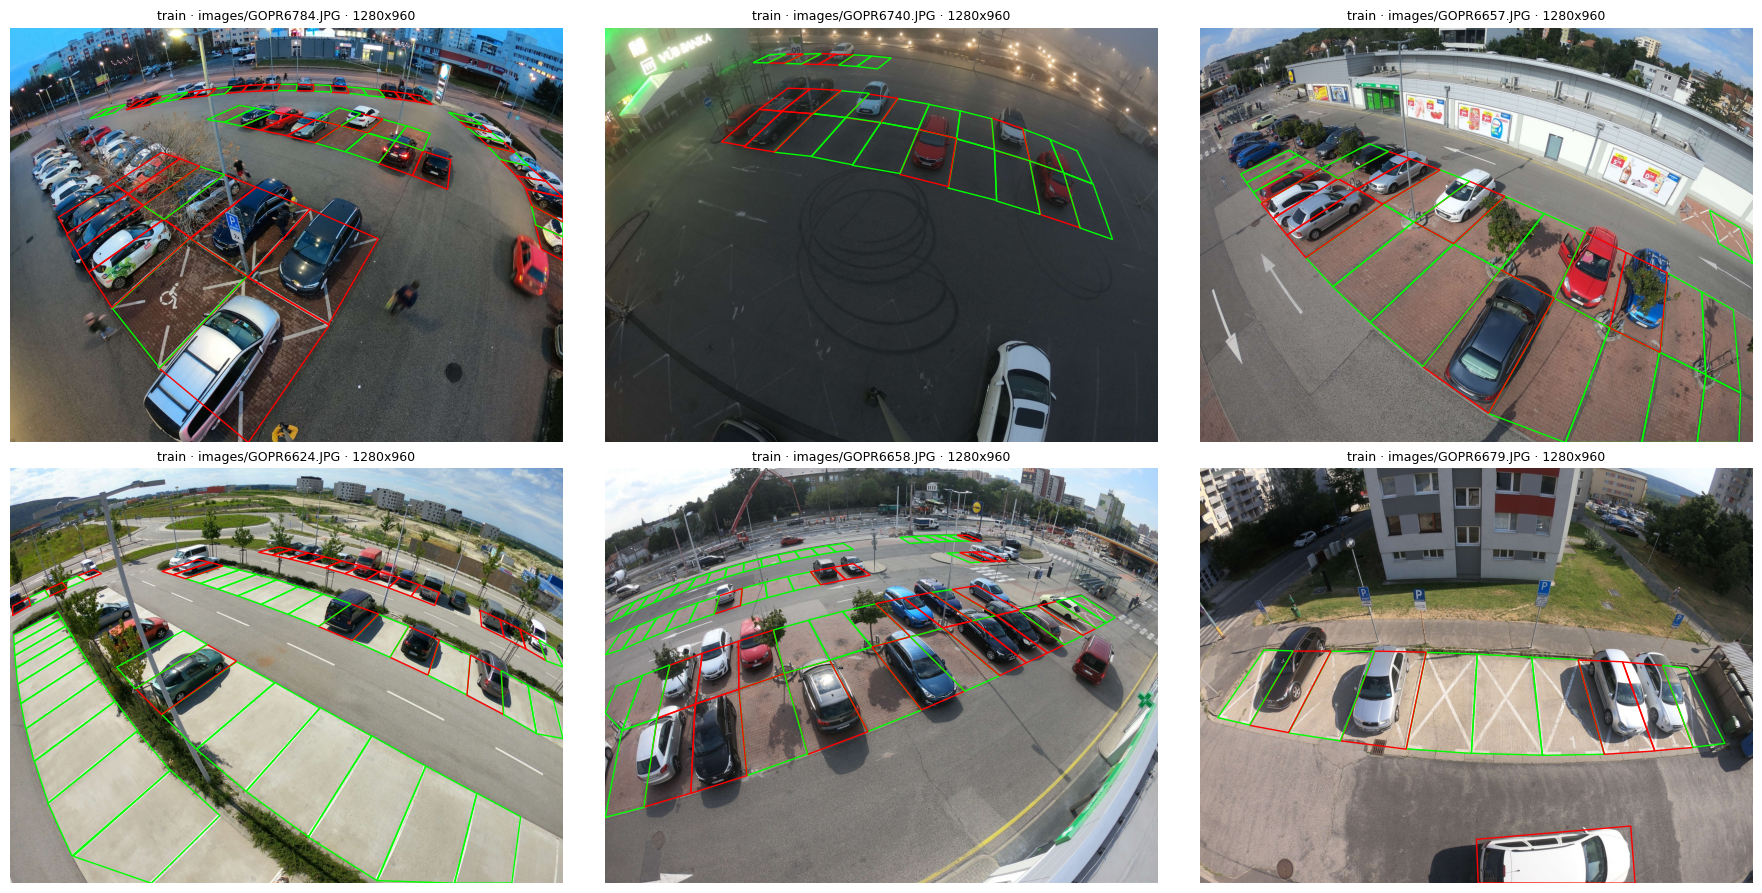

In [8]:

# ===================== CELDA 7: verificación visual =====================
import random
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

COLORS = {1: 'lime', 2: 'red'}
spots_by_image = {}
for a in coco['annotations']:
    spots_by_image.setdefault(a['image_id'], []).append(a)

random.seed(99)
sample = random.sample(coco['images'], min(6, len(coco['images'])))
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax in axes.flat:
    ax.axis('off')
for ax, im in zip(axes.flat, sample):
    with Image.open(os.path.join(OUT_DIR, im['file_name'])) as photo:
        ax.imshow(photo.copy())
    for a in spots_by_image.get(im['id'], []):
        pts = list(zip(a['segmentation'][0][::2], a['segmentation'][0][1::2]))
        ax.add_patch(Polygon(pts, fill=False, edgecolor=COLORS[a['category_id']],
                             linewidth=1, linestyle='--' if a['truncated'] else '-'))
    ax.set_title(f"{im['split']} · {im['original']['file_name']} · {im['width']}x{im['height']}", fontsize=9)
plt.tight_layout()

In [9]:

# ===================== CELDA 8: revisar las plazas con X =====================
# Guarda una imagen por cada foto con X: las plazas marcadas en amarillo, el resto
# en verde/rojo. Sirve para confirmar la lista antes de dar el dataset por bueno.
import zipfile
from PIL import ImageDraw

CHECK_DIR = f'{BASE}/acpds_marked_x_check'
os.makedirs(CHECK_DIR, exist_ok=True)
images_by_id = {im['id']: im for im in coco['images']}
with_x = sorted({a['image_id'] for a in coco['annotations'] if a['marked_x']})
for iid in with_x:
    im = images_by_id[iid]
    with Image.open(os.path.join(OUT_DIR, im['file_name'])) as photo:
        canvas = photo.convert('RGB')
    overlay = Image.new('RGBA', canvas.size, (0, 0, 0, 0))
    draw = ImageDraw.Draw(overlay)
    for a in spots_by_image[iid]:
        pts = list(zip(a['segmentation'][0][::2], a['segmentation'][0][1::2]))
        if a['marked_x']:
            draw.polygon(pts, fill=(255, 220, 0, 110), outline=(255, 220, 0, 255))
        else:
            color = (255, 60, 60, 255) if a['category_id'] == 2 else (60, 220, 60, 255)
            draw.polygon(pts, outline=color)
    canvas = Image.alpha_composite(canvas.convert('RGBA'), overlay).convert('RGB')
    name = os.path.splitext(os.path.basename(im['original']['file_name']))[0]
    canvas.save(os.path.join(CHECK_DIR, f'{name}.jpg'), quality=80)

check_zip = f'{BASE}/acpds_marked_x_check.zip'
with zipfile.ZipFile(check_zip, 'w') as z:
    for f in sorted(os.listdir(CHECK_DIR)):
        z.write(os.path.join(CHECK_DIR, f), f)
print('Imágenes con plazas X:', len(with_x), '| zip:', check_zip)


Imágenes con plazas X: 51 | zip: /content/acpds_marked_x_check.zip


In [10]:
from google.colab import files
files.download('/content/acpds_marked_x_check.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
!zip -qr /content/ACPDS-coco.zip /content/data/ACPDS-coco
files.download('/content/ACPDS-coco.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>